# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

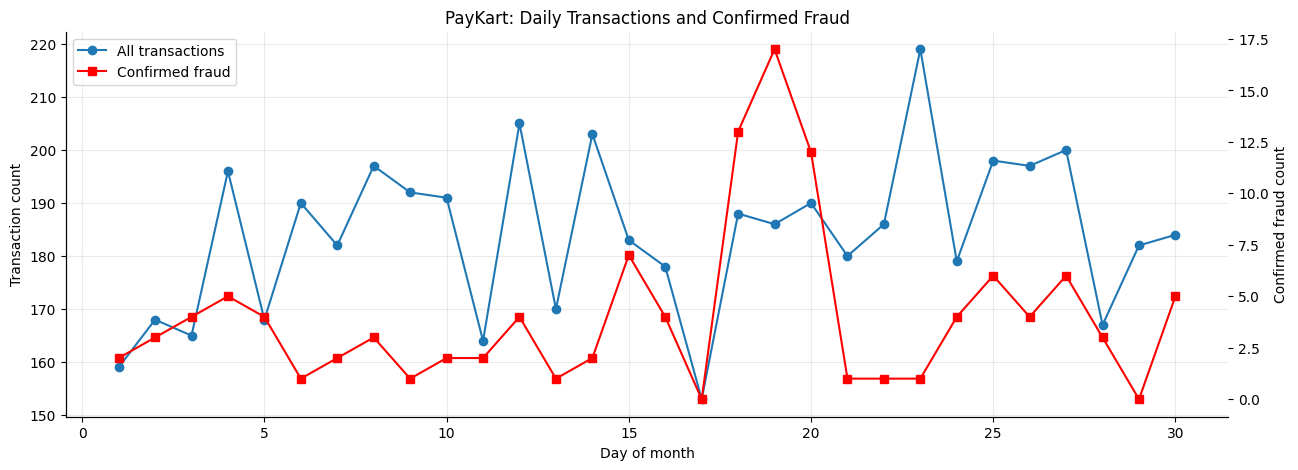

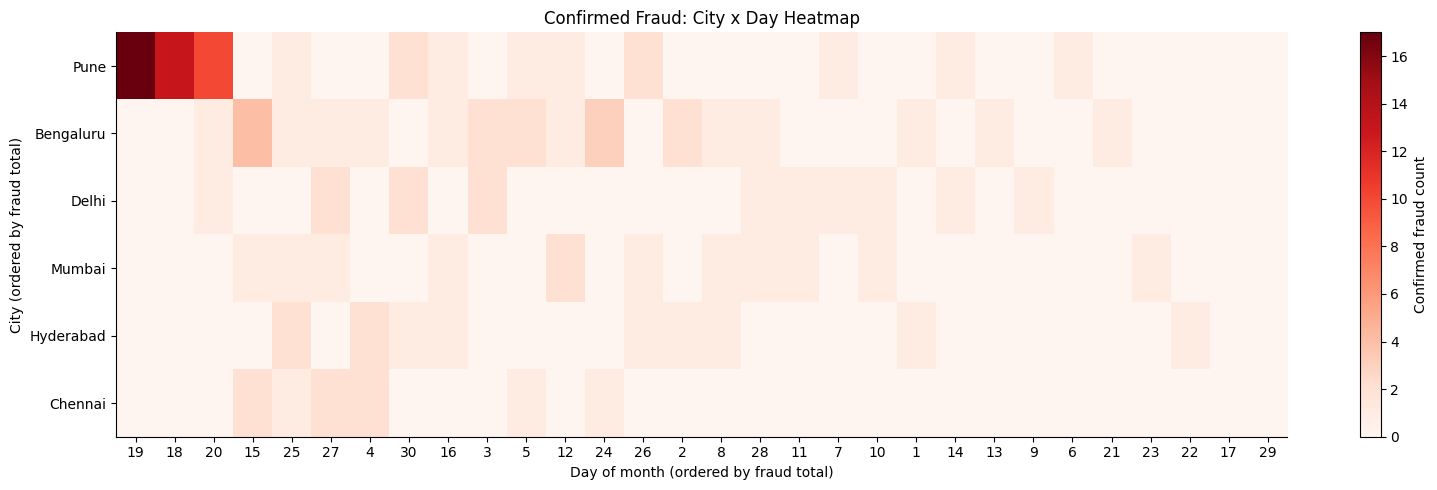

Top city-day combinations by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Chennai    4       2
Bengaluru  3       2
Hyderabad  25      2
Pune       26      2
Chennai    15      2
Name: is_fraud, dtype: int64


In [2]:
# TODO 1: daily transaction counts and confirmed fraud
daily = tx.groupby("day").agg(
    transactions=("txn_id", "size"),
    fraud=("is_fraud", "sum")
)

fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(
    daily.index, daily["transactions"],
    marker="o", label="All transactions"
)
ax1.set_xlabel("Day of month")
ax1.set_ylabel("Transaction count")
ax1.set_title("PayKart: Daily Transactions and Confirmed Fraud")
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(
    daily.index, daily["fraud"],
    color="red", marker="s", label="Confirmed fraud"
)
ax2.set_ylabel("Confirmed fraud count")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# TODO 2: city x day confirmed-fraud count heatmap
heat = tx.pivot_table(
    index="city",
    columns="day",
    values="is_fraud",
    aggfunc="sum",
    fill_value=0
)

# Reorder cities and days by their fraud totals
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(16, 5))

im = ax.imshow(heat, aspect="auto", cmap="Reds")

ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(heat.index)

ax.set_xlabel("Day of month (ordered by fraud total)")
ax.set_ylabel("City (ordered by fraud total)")
ax.set_title("Confirmed Fraud: City x Day Heatmap")

plt.colorbar(im, ax=ax, label="Confirmed fraud count")
plt.tight_layout()
plt.show()

# TODO 3: city-day cells with the most fraud
top_cells = (
    tx.groupby(["city", "day"])["is_fraud"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top city-day combinations by confirmed fraud:")
print(top_cells)

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
An overview revealed a concentration of confirmed fraud in Pune around days 18–20, which would not be obvious from an alert list sorted by detector score. The daily line chart showed when fraud increased, while the reordered city-by-day heatmap exposed the location and timing of the concentration. This demonstrates the concept of **visual pattern detection through reordering**, alongside Shneiderman's mantra of overview first, zoom and filter, then details on demand.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

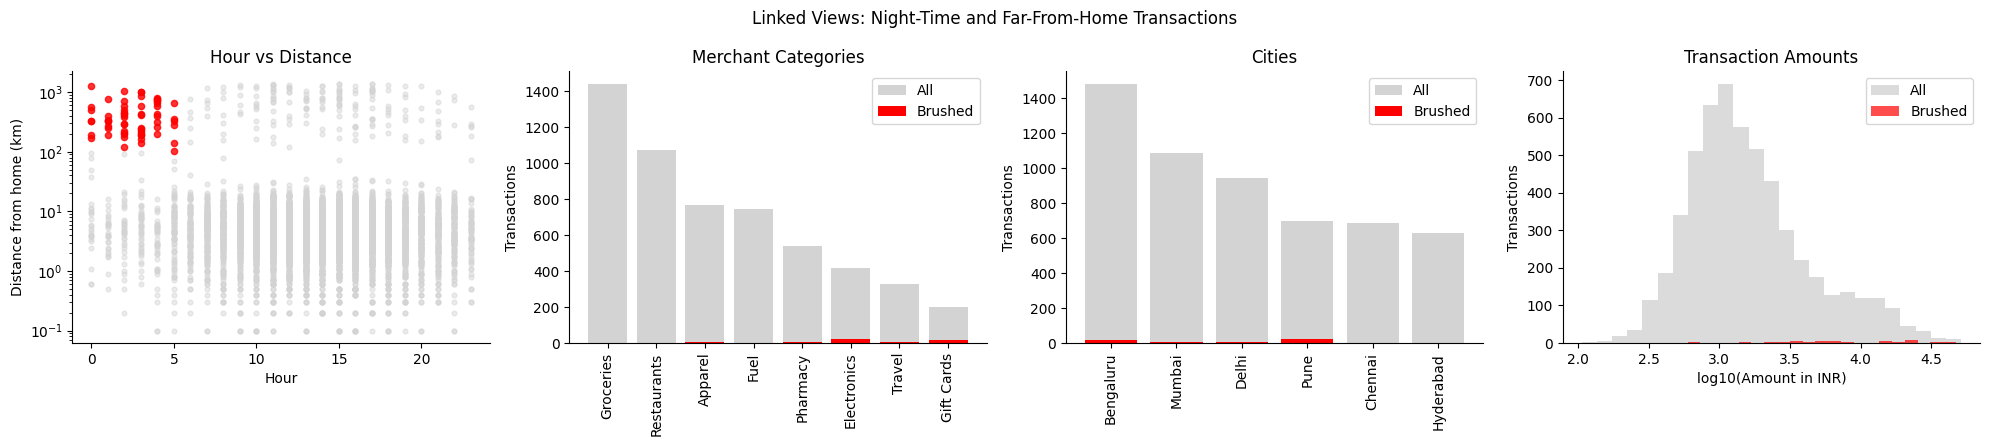

Brushed transactions: 61
Confirmed fraud in brush: 53
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured: 44.17%


In [3]:
# TODO 1: define the brush
brush = (
    (tx["night"]) &
    (tx["distance_from_home_km"] > 100)
)

# TODO 2: four linked views
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

# (a) Hour vs distance scatter, logarithmic y-axis
axes[0].scatter(
    tx.loc[~brush, "hour"],
    tx.loc[~brush, "distance_from_home_km"],
    color="lightgray", alpha=0.45, s=12
)
axes[0].scatter(
    tx.loc[brush, "hour"],
    tx.loc[brush, "distance_from_home_km"],
    color="red", alpha=0.8, s=20
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs Distance")

# (b) Merchant category counts
categories = tx["merchant_category"].value_counts().index

all_cat = tx["merchant_category"].value_counts().reindex(
    categories, fill_value=0
)
brush_cat = tx.loc[brush, "merchant_category"].value_counts().reindex(
    categories, fill_value=0
)

axes[1].bar(categories, all_cat, color="lightgray", label="All")
axes[1].bar(categories, brush_cat, color="red", label="Brushed")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("Merchant Categories")
axes[1].set_ylabel("Transactions")
axes[1].legend()

# (c) City counts
cities = tx["city"].value_counts().index

all_city = tx["city"].value_counts().reindex(cities, fill_value=0)
brush_city = tx.loc[brush, "city"].value_counts().reindex(
    cities, fill_value=0
)

axes[2].bar(cities, all_city, color="lightgray", label="All")
axes[2].bar(cities, brush_city, color="red", label="Brushed")
axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("Cities")
axes[2].set_ylabel("Transactions")
axes[2].legend()

# (d) Amount histogram using log10 scale
axes[3].hist(
    np.log10(tx.loc[~brush, "amount_inr"].clip(lower=1)),
    bins=25, color="lightgray", alpha=0.8, label="All"
)
axes[3].hist(
    np.log10(tx.loc[brush, "amount_inr"].clip(lower=1)),
    bins=25, color="red", alpha=0.7, label="Brushed"
)
axes[3].set_xlabel("log10(Amount in INR)")
axes[3].set_ylabel("Transactions")
axes[3].set_title("Transaction Amounts")
axes[3].legend()

plt.suptitle("Linked Views: Night-Time and Far-From-Home Transactions")
plt.tight_layout()
plt.show()

# TODO 3: calculate brush statistics
n_brushed = int(brush.sum())
fraud_in_brush = int(tx.loc[brush, "is_fraud"].sum())
fraud_total = int(tx["is_fraud"].sum())

brush_rate = tx.loc[brush, "is_fraud"].mean()
overall_rate = tx["is_fraud"].mean()
fraud_capture = fraud_in_brush / fraud_total

print(f"Brushed transactions: {n_brushed}")
print(f"Confirmed fraud in brush: {fraud_in_brush}")
print(f"Fraud rate inside brush: {brush_rate:.2%}")
print(f"Overall fraud rate: {overall_rate:.2%}")
print(f"Share of all fraud captured: {fraud_capture:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The rule identifies 61 transactions, of which 53 are confirmed fraud, giving a fraud rate of approximately 86.89%. However, it captures only 44.17% of all confirmed fraud, so relying on this rule alone would miss more than half of the fraud cases. The linked city and merchant-category views help investigators investigate the transactions that fall outside the rule, including fraud occurring during daytime hours or closer to home.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
# Build approximately 1 million rows
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: benchmark the filter, taking the best of five runs
times = []

for _ in range(5):
    start = time.perf_counter()

    result = (
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    )

    elapsed = time.perf_counter() - start
    times.append(elapsed)

best_s = min(times)

# TODO 2: cost per row and maximum rows within 0.1 seconds
per_item_us = best_s / len(big) * 1_000_000

seconds_per_row = best_s / len(big)
max_rows = 0.1 / seconds_per_row

# TODO 3: estimate for 50 million rows
t_50m = seconds_per_row * 50_000_000

skip_pct = max(
    0,
    (1 - 0.1 / t_50m) * 100
)

print(
    f"{len(big):,} rows in {best_s*1000:.1f} ms -> "
    f"{per_item_us:.4f} us/row -> "
    f"max {max_rows:,.0f} rows in 0.1 s"
)

print(
    f"50M rows -> {t_50m:.2f} s; "
    f"must skip {skip_pct:.1f}% of rows to stay under 0.1 s"
)

1,004,640 rows in 4.1 ms -> 0.0041 us/row -> max 24,302,257 rows in 0.1 s
50M rows -> 0.21 s; must skip 51.4% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
Besides indexing, I would use **sampling**, a reduce technique that displays a representative subset of transactions instead of processing every record for each interaction. This can make the slider more responsive on 50 million rows. However, the analyst loses visibility into some individual transactions, and rare fraud cases may be omitted from the sample. For final fraud investigations, the system should still allow exact filtering against the complete dataset.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

Threshold evaluation:


,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.0567,0.9500,0.1069
1,0.10,1167,111,1056,9,0.0951,0.9250,0.1725
2,0.15,786,110,676,10,0.1399,0.9167,0.2428
3,0.20,596,106,490,14,0.1779,0.8833,0.2961
4,0.25,471,105,366,15,0.2229,0.8750,0.3553
5,0.30,401,104,297,16,0.2594,0.8667,0.3992
6,0.35,355,104,251,16,0.2930,0.8667,0.4379
7,0.40,319,104,215,16,0.3260,0.8667,0.4738
8,0.45,283,104,179,16,0.3675,0.8667,0.5161
9,0.50,260,101,159,19,0.3885,0.8417,0.5316


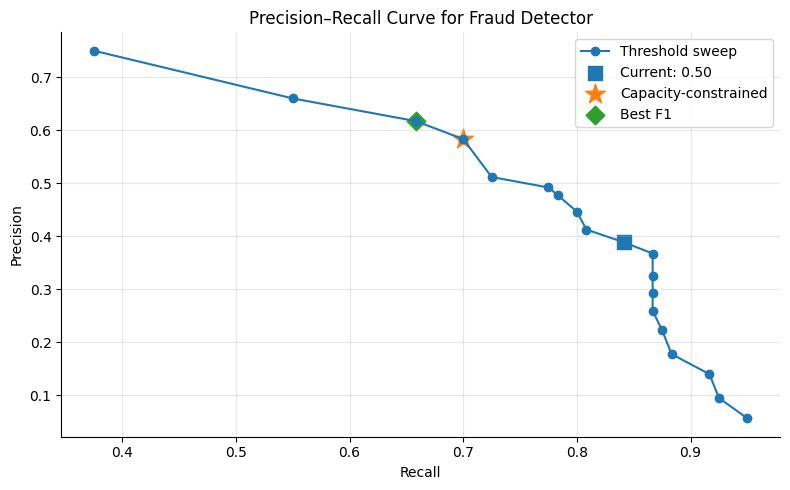

Recommendation: use threshold 0.80. It flags 144 alerts, with precision 58.3%, recall 70.0%, and F1 0.636, meeting the 150-alert capacity.
Best-F1 threshold: 0.85, with 128 alerts and F1 0.637.


In [5]:
rows = []

# TODO 1: evaluate thresholds from 0.05 to 0.95
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    predicted = tx["detector_score"] >= threshold
    actual = tx["is_fraud"] == 1

    TP = int((predicted & actual).sum())
    FP = int((predicted & ~actual).sum())
    FN = int((~predicted & actual).sum())

    alerts = int(predicted.sum())

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    F1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "threshold": threshold,
        "alerts": alerts,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": F1
    })

pr = pd.DataFrame(rows)

print("Threshold evaluation:")
display(pr.round(4))

# TODO 2: highest recall subject to capacity <= 150 alerts
feasible = pr[pr["alerts"] <= 150]

capacity_choice = feasible.sort_values(
    ["recall", "threshold"],
    ascending=[False, True]
).iloc[0]

# Best F1 across all thresholds
best_f1 = pr.loc[pr["F1"].idxmax()]

# TODO 3: precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pr["recall"], pr["precision"],
    marker="o", label="Threshold sweep"
)

# Current threshold = 0.5
current = pr.loc[pr["threshold"] == 0.50].iloc[0]

ax.scatter(
    current["recall"], current["precision"],
    marker="s", s=100, label="Current: 0.50"
)

ax.scatter(
    capacity_choice["recall"], capacity_choice["precision"],
    marker="*", s=220, label="Capacity-constrained"
)

ax.scatter(
    best_f1["recall"], best_f1["precision"],
    marker="D", s=90, label="Best F1"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve for Fraud Detector")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: recommendation
print(
    f"Recommendation: use threshold {capacity_choice['threshold']:.2f}. "
    f"It flags {int(capacity_choice['alerts'])} alerts, with "
    f"precision {capacity_choice['precision']:.1%}, "
    f"recall {capacity_choice['recall']:.1%}, and "
    f"F1 {capacity_choice['F1']:.3f}, meeting the 150-alert capacity."
)

print(
    f"Best-F1 threshold: {best_f1['threshold']:.2f}, "
    f"with {int(best_f1['alerts'])} alerts and "
    f"F1 {best_f1['F1']:.3f}."
)

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops should make the final threshold decision, with the model providing evidence through precision, recall, F1, and the number of alerts generated. In this dataset, a threshold of 0.80 produces 144 alerts, with approximately 58.33% precision and 70% recall, satisfying the monthly capacity limit. The best-F1 threshold is 0.85, which produces 128 alerts and a slightly higher F1 score, but detects fewer fraud cases. Visual analytics keeps a human in the loop because the appropriate balance depends on investigation capacity, financial risk, and the consequences of missed fraud, not just on a mathematical score.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: interactive scatter of transactions with detector score >= 0.3
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=[
        "txn_id",
        "customer_id",
        "city",
        "merchant_category",
        "distance_from_home_km",
        "detector_score"
    ],
    title="Flagged Transactions: Investigative Explorer",
    labels={
        "timestamp": "Transaction time",
        "amount_inr": "Amount (INR)",
        "label": "Investigation label"
    },
    color_discrete_map={
        "confirmed fraud": "red",
        "legitimate": "gray"
    }
)

fig.update_layout(dragmode="select")
fig.show()

print(f"Flagged transactions at score >= 0.3: {len(flagged)}")

# TODO 2: sunburst drill-down from city to merchant category
sunburst_data = (
    tx.groupby(["city", "merchant_category"])
    .agg(
        transaction_count=("txn_id", "size"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

fig_sun = px.sunburst(
    sunburst_data,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="Reds",
    range_color=(0, 1),
    hover_data={
        "transaction_count": True,
        "fraud_rate": ":.2%"
    },
    title="Fraud Investigation: City → Merchant Category"
)

fig_sun.show()

Flagged transactions at score >= 0.3: 401


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips are frustrating for an overview of 400 flagged cases because investigators must hover over transactions one at a time and remember the details while comparing them. This makes it difficult to notice clusters, outliers, or broader patterns. The scatter plot provides an overview of the flagged cases, while the sunburst chart supports drill-down from city to merchant category. Together, these views follow Shneiderman's mantra of overview first, then zoom and filter, then details on demand.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18-20.
Transactions inside window: 107
Fraud inside window: 40
Fraud rate inside: 37.38%
Fraud rate outside: 1.48%
Chi-square statistic: 619.294
p-value: 1.065e-136


,Group,Transactions,Confirmed fraud,Fraud rate
0,"Pune, days 18-20",107,40,37.38%
1,"Pune, other days",593,11,1.85%
2,"Other cities, days 18-20",457,2,0.44%
3,"Other cities, other days",4363,67,1.54%


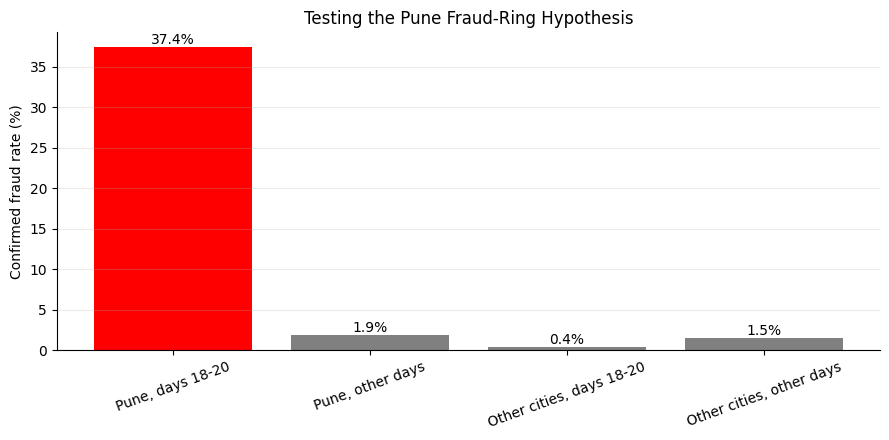

VERDICT: The data supports a statistically significant fraud concentration in the selected city-day window. This does not by itself prove a coordinated fraud ring.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis window
hot_city = "Pune"
start_day = 18
end_day = 20

in_window = (
    tx["city"].eq(hot_city) &
    tx["day"].between(start_day, end_day)
)

print(
    f"Hypothesis: confirmed fraud is unusually concentrated in "
    f"{hot_city} on days {start_day}-{end_day}."
)

# TODO 2: compare fraud rates and calculate chi-square p-value
fraud_rate_inside = tx.loc[in_window, "is_fraud"].mean()
fraud_rate_outside = tx.loc[~in_window, "is_fraud"].mean()

contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Transactions inside window: {int(in_window.sum())}")
print(
    f"Fraud inside window: "
    f"{int(tx.loc[in_window, 'is_fraud'].sum())}"
)
print(f"Fraud rate inside: {fraud_rate_inside:.2%}")
print(f"Fraud rate outside: {fraud_rate_outside:.2%}")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"p-value: {p_value:.3e}")

# TODO 3: counter-example searches
same_city_other_days = (
    tx["city"].eq(hot_city) &
    ~tx["day"].between(start_day, end_day)
)

other_cities_same_days = (
    ~tx["city"].eq(hot_city) &
    tx["day"].between(start_day, end_day)
)

rest = (
    ~tx["city"].eq(hot_city) &
    ~tx["day"].between(start_day, end_day)
)

groups = {
    "Pune, days 18-20": in_window,
    "Pune, other days": same_city_other_days,
    "Other cities, days 18-20": other_cities_same_days,
    "Other cities, other days": rest
}

summary_rows = []

for name, mask in groups.items():
    n = int(mask.sum())
    fraud_count = int(tx.loc[mask, "is_fraud"].sum())
    fraud_rate = (
        fraud_count / n if n else 0
    )

    summary_rows.append({
        "Group": name,
        "Transactions": n,
        "Confirmed fraud": fraud_count,
        "Fraud rate": fraud_rate
    })

group_summary = pd.DataFrame(summary_rows)
display(group_summary.style.format({"Fraud rate": "{:.2%}"}))

# TODO 4: visual confirmation
fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(
    group_summary["Group"],
    group_summary["Fraud rate"] * 100,
    color=["red", "gray", "gray", "gray"]
)

ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Testing the Pune Fraud-Ring Hypothesis")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)

for bar, rate in zip(bars, group_summary["Fraud rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1%}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# TODO 5: verdict
if fraud_rate_inside > fraud_rate_outside and p_value < 0.05:
    print(
        "VERDICT: The data supports a statistically significant "
        "fraud concentration in the selected city-day window. "
        "This does not by itself prove a coordinated fraud ring."
    )
else:
    print(
        "VERDICT: The data does not provide sufficient evidence "
        "of a statistically significant fraud concentration "
        "in the selected city-day window."
    )

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_
The search for fraud in Pune on other days would have weakened the hypothesis if it had found a similarly high fraud rate, because that would suggest a persistent city-specific issue rather than a short-lived event. The search across other cities during days 18–20 would also be important: a similarly high rate elsewhere would support an alternative explanation such as a wider, time-related fraud campaign. In the actual dataset, both comparison groups have much lower fraud rates than the Pune window. This supports a concentrated anomaly, but transaction patterns alone cannot establish that the cases were coordinated by a fraud ring.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_


PayKart recorded 5,520 transactions and 120 confirmed fraud cases last month, with 40 of the 120 fraud cases concentrated in Pune over days 18–20, where 37.38% of transactions were fraudulent. I recommend raising the detector threshold from 0.50 to 0.80, which produces 144 alerts within the monthly capacity of 150, with 58.33% precision and 70% recall; the Head of Fraud Ops should approve this trade-off because the best-F1 threshold of 0.85 misses more fraud cases. The first interactive view to build should be the flagged-transaction scatter plot, because investigators can select suspicious clusters, filter transactions, and inspect case details on demand. The benchmark should be used to confirm that filtering stays within the 0.1-second response budget, with indexing or pre-aggregation added if needed for the full 50-million-row history. Finally, introduce an investigator feedback loop in which confirmed fraud and legitimate-case outcomes are recorded, reviewed, used to improve training labels and retrain the detector, and evaluated against the next month's precision, recall, and alert capacity.